In [25]:
import matplotlib.pyplot as plt
import numpy as np

from amms.core import products
from amms.core.analysis.sfr import lookback_edges, sfh, sfr_map_from_young_stars
from amms.core.datasets import b12, patel2020
from amms.core.analysis import units
from amms.core.plotting.maps import shared_norm, show_map

DATASET, DT = "ext_b12-model2", 0.01 # kpc, Gyr
LMC_R_MAX = 5.0
SMC_R_MAX = 2.0

# Loading functions

In [26]:
def load_sfh(galaxy, snap=69, r_max=LMC_R_MAX, dt=DT):
    p = products.read_product(products.product_path(DATASET, "newstars", f"{galaxy}-{snap:03d}"))
    t_now = p.attrs.meta["t_now_gyr"]
    edges = lookback_edges(t_now, dt)
    pos, t, m = p.arrays["pos_kpc"], p.arrays["t_form_gyr"], p.arrays["mass_msun"]
    sel = np.linalg.norm(pos, axis=1) < r_max # position is already in the galaxy's own frame
    _, rate = sfh(t[sel], m[sel], bins=edges)
    _, rate_all = sfh(t, m, bins=edges)
    return p, t_now, edges, rate, rate_all

In [27]:
def load_orbits(model):
    ds = f"ext_b12-model{model}"
    o = {g: products.read_product(products.product_path(ds, "orbit", g)).arrays for g in ("lmc", "smc")}
    assert np.array_equal(o["lmc"]["snapshot"], o["smc"]["snapshot"])
    # present day taken from the same header that the newstars product used
    # SFH and orbit panels then share t_now
    t_now = float(o["lmc"]["t_gyr"][o["lmc"]["snapshot"] == b12.SNAP_PRESENT_DAY][0])
    return o, t_now

# SFR

## SMC

In [28]:
p = products.read_product(products.product_path("ext_b12-model2", "newstars", "smc-069"))
age = p.attrs.meta["t_now_gyr"] - p.arrays["t_form_gyr"]
maps = [sfr_map_from_young_stars(p.arrays["pos_kpc"], p.arrays["mass_msun"], age,
                                 dt=0.1, axes=ax, extent=10.0, bins=40) for ax in ("xy", "xz")]
norm = shared_norm(maps, percentiles=(1, 99.5), min_counts=3)

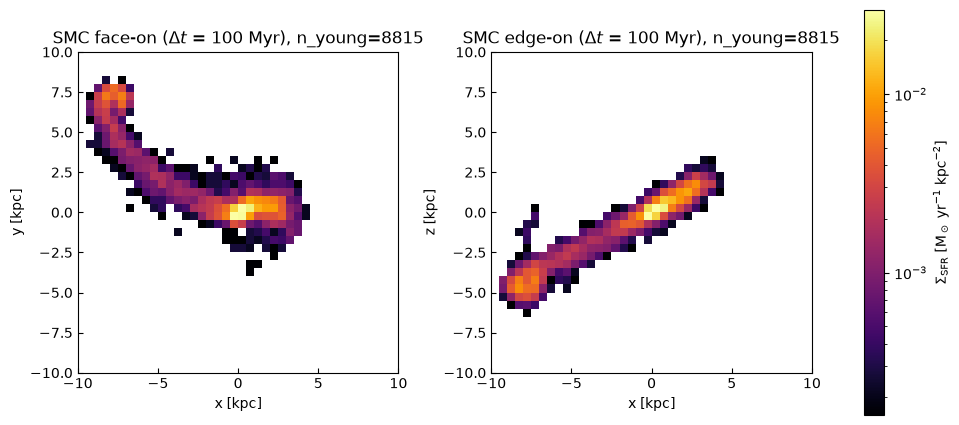

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), constrained_layout=True)
for ax, m, title in zip(axes, maps, ("face-on", "edge-on")):
    im = show_map(m, ax, norm=norm, min_counts=3, cmap="inferno", cbar=False)
    ax.set_title(f"SMC {title} ($\\Delta t$ = 100 Myr), n_young={m.meta['n_young']}")
fig.colorbar(im, ax=list(axes), label=r"$\Sigma_{\rm SFR}$ [M$_\odot$ yr$^{-1}$ kpc$^{-2}$]")

# SFH

## LMC

0.9778 t_now 0.9638314273225411 dropped ft==0 315969
PIN all LMC stars, last 100 Myr: 0.032783578011017264 (0.0488 with the old 0.97)


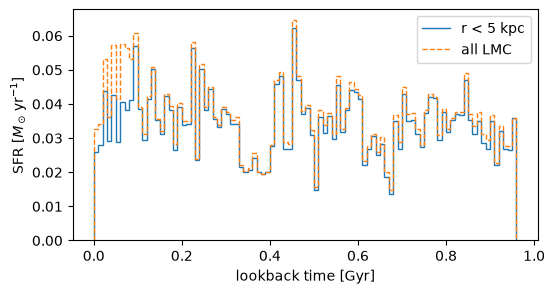

In [30]:
p, t_now, edges, rate, rate_all = load_sfh("lmc")
print(p.attrs.meta["gadget_time_to_gyr"], "t_now", t_now, "dropped ft==0", p.attrs.meta["n_dropped_ft0"])
print("PIN all LMC stars, last 100 Myr:", rate_all[-1], "(0.0488 with the old 0.97)")

fig, ax = plt.subplots(figsize=(6, 3))
# reversed so stairs get increasing lookback edges with 0 as the present day
ax.stairs(rate[::-1], (t_now - edges)[::-1], label=f"r < {LMC_R_MAX:g} kpc")
ax.stairs(rate_all[::-1], (t_now - edges)[::-1], ls="--", label="all LMC")
ax.set(xlabel="lookback time [Gyr]", ylabel=r"SFR [$M_\odot\,\mathrm{yr}^{-1}$]")
ax.legend()

## SMC

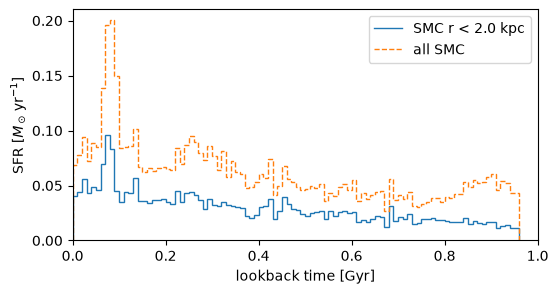

In [31]:

p, t_now, edges, rate, rate_all = load_sfh("smc", r_max=SMC_R_MAX)

fig, ax = plt.subplots(figsize=(6,3))
ax.stairs(rate[::-1], (t_now - edges)[::-1], label=f"SMC r < {SMC_R_MAX} kpc")
ax.stairs(rate_all[::-1], (t_now - edges)[::-1], ls="--", label="all SMC")
ax.set(xlabel="lookback time [Gyr]", ylabel=r"SFR [$M_\odot\,\mathrm{yr}^{-1}$]", xlim=(0, 1))
ax.legend()

# Orbits

In [32]:
for model in (2, 1):
    o, t_now = load_orbits(model)
    for g, a in o.items():
        v_fd = np.linalg.norm(np.diff(a["pos_kpc"], axis=0), axis=1) / np.diff(a["t_gyr"]) / units.KPC_PER_GYR_PER_KMS
        speed = np.linalg.norm(a["vel_kms"], axis=1)
        ratio = v_fd / (0.5 * (speed[1:] + speed[:-1]))
        worst = int(np.argmax(np.abs(ratio - 1)))
        print(f"M{model} {g}: ratio {ratio.min():.3f}-{ratio.max():.3f}, worst at snap {a['snapshot'][worst + 1]}")

M2 lmc: ratio 0.953-1.048, worst at snap 5
M2 smc: ratio 0.939-1.047, worst at snap 16
M1 lmc: ratio 0.972-1.038, worst at snap 36
M1 smc: ratio 0.913-1.053, worst at snap 5


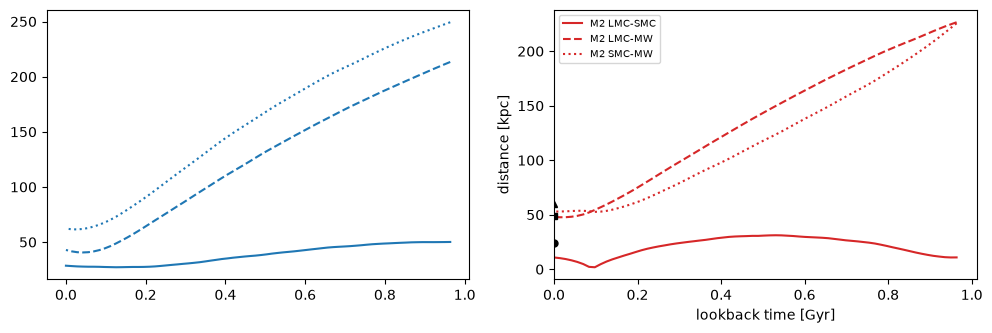

In [33]:
COLOR= {1: "C0", 2: "C3"}
MODELS = (1, 2)

fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.5))
for i, model in enumerate(MODELS):
    ax = axes[i]
    o, t_now = load_orbits(model)
    lmc, smc = o["lmc"], o["smc"]
    lb = t_now - lmc["t_gyr"]
    keep = lb >= -1e-9 # only keep up to present day
    c = COLOR[model]
    ax.plot(lb[keep], np.linalg.norm(lmc["pos_kpc"] - smc["pos_kpc"], axis=1)[keep], c=c, label=f"M{model} LMC-SMC")
    ax.plot(lb[keep], np.linalg.norm(lmc["pos_kpc"], axis=1)[keep], c=c, ls="--", label=f"M{model} LMC-MW")
    ax.plot(lb[keep], np.linalg.norm(smc["pos_kpc"], axis=1)[keep], c=c, ls=":", label=f"M{model} SMC-MW")

# Add in the present day location from Patel+2020 at lookback=0
L, S = np.asarray(patel2020.LMC_CENTER), np.asarray(patel2020.SMC_CENTER)
for d, mk in ((np.linalg.norm(L - S), "o"), (np.linalg.norm(L), "s"), (np.linalg.norm(S), "^")):
    ax.plot(0, d, mk, c="k", ms=5)
ax.set(xlabel="lookback time [Gyr]", ylabel="distance [kpc]", xlim=(0, None))
ax.legend(fontsize=7)
# ax.invert_xaxis()